## 作业

In [34]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv

#加载.env文件中的环境变量
load_dotenv()

#创建模型
model = init_chat_model("gpt-5.4-nano")

In [ ]:
from langchain.tools import tool

@tool
def check_order_status(order_id: str):
    """根据订单号查询订单状态，返回"已发货"、"配送中"、"已签收"等状态"""
    orders = {
        "order1": {"status": "已发货","product":"手机", "address": "深圳市南山区"},
        "order2": {"status": "配送中","product":"电脑", "address": "深圳市龙华区"},
        "order3": {"status": "已签收","product":"平板", "address": "深圳市罗湖区"},
        "order4": {"status": "已发货","product":"耳机", "address": "深圳市福田区"},
    }
    if order_id in orders:
        return f"订单号{order_id}的状态是{orders[order_id]['status']},商品是{orders[order_id]['product']},收货地址是{orders[order_id]['address']}"
    else:
        return "订单不存在"

@tool    
def get_product_info(product_name: str):
    """根据商品名称返回商品信息，包含价格、库存、描述"""
    products ={
        "手机": {"price": "3999元", "stock": "100台", "description": "华为P50，麒麟9000芯片，5G网络，超感光徕卡四摄"},
        "Apple手机": {"price": "5999元", "stock": "50台", "description": "iPhone 13，A15芯片，5G网络，超视网膜XDR显示屏"},
        "Xiaomi手机": {"price": "2999元", "stock": "200台", "description": "小米11，骁龙888芯片，5G网络，6400万像素四摄"}
    }
    
    if product_name in products:
        return f"商品名称：{product_name}\n价格：{products[product_name]['price']}\n库存：{products[product_name]['stock']}\n描述：{products[product_name]['description']}"
    else:
        return "商品不存在"

@tool    
def calculate_delivery_time(city: str):
    """根据城市计算预计送达时间"""
    delivery_times = {
        "北京市": "2-3天",
        "上海市": "1-2天",
        "广州市": "3-5天",
        "深圳市": "2-4天"
    }

    if city in delivery_times:
        return f"预计送达时间：{delivery_times[city]}"
    else:
        return "该城市不支持配送"

In [36]:
agent = create_agent(
    model,
    tools=[check_order_status, get_product_info, calculate_delivery_time], 
    system_prompt="你是一个智能客服，请根据用户的问题提供相应的回答")
query = "我想查询订单号order1的状态,顺便看看Huawei手机商品信息，以及送到上海预计送达时间？"
for mode, chunk in agent.stream({
    "messages":[{'role':'user', 'content':query}]
}, stream_mode=["updates", "messages"]):
    if mode == "updates":
        #包括每个状态的更新：model和tools的状态信息，包括工具名称以及参数
        # HARNES
        for node, data in chunk.items():
            messages = data.get("messages", []) #每个节点处理后的消息
            if messages:
                last_msg = messages[-1]
                # 判断是否需要调用工具
                if hasattr(last_msg, "tool_calls") and last_msg.tool_calls:
                    for tool_call in last_msg.tool_calls:
                        print(f"调用工具：{tool_call["name"]}，参数：{tool_call["args"]}")
                
                # 判断工具执行后的结果
                elif hasattr(last_msg, "name") and last_msg.name:
                    print(f"工具执行结果：{last_msg.name}-->{last_msg.content}")
    elif mode == "messages":
        #模型的输出token
        token =  chunk[0] 
        metadata = chunk[1]
        if metadata.get("langgraph_node") == "model": #表示模型的输出结果
            for block in token.content:
                print(block, end="", flush=True)

调用工具：check_order_status，参数：{'order_id': 'order1'}
调用工具：get_product_info，参数：{'product_name': 'Huawei手机'}
调用工具：calculate_delivery_time，参数：{'city': '上海'}
工具执行结果：check_order_status-->订单号order1的状态是已发货,商品是Huawei手机,收货地址是北京市海淀区
工具执行结果：get_product_info-->商品名称：Huawei手机
价格：3999元
库存：100台
描述：华为P50，麒麟9000芯片，5G网络，超感光徕卡四摄
工具执行结果：calculate_delivery_time-->该城市不支持配送
当然可以，我帮您一起查了：

1) **订单状态（order1）**：已发货  
2) **商品信息（Huawei手机）**：  
- 价格：3999元  
- 库存：100台  
- 描述：华为P50，麒麟9000芯片，5G网络，超感光徕卡四摄  
3) **预计送达时间（上海）**：该城市不支持配送

如果您想，我也可以根据您的实际收货城市再帮您重新查询预计送达时间。您方便提供一下收货城市/区吗？

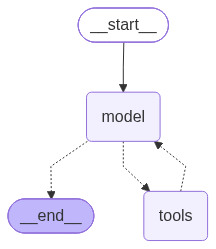

In [38]:
agent

## MCP

In [39]:

from langchain_mcp_adapters.client import MultiServerMCPClient

client = MultiServerMCPClient(
    {
        "weather":{
            "transport":"streamable-http",
            "url":"http://127.0.0.1:8000/mcp"
        },
        "hotel": {
            "transport":"streamable-http",
            "url":"http://127.0.0.1:8001/mcp"
        },
        "amap-maps":{
            "transport":"streamable-http", 
            "url":"https://mcp.amap.com/mcp?key=c9ff46af8bc64a009c9b2b7f648bb339"
        }        
})


In [40]:
tools = await client.get_tools()
print(tools)

[StructuredTool(name='get_weather', description='获取指定城市的天气信息', args_schema={'properties': {'city': {'title': 'City', 'type': 'string'}}, 'required': ['city'], 'title': 'get_weatherArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x00000267501C6DE0>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x00000267503C05E0>), StructuredTool(name='search_hotel', description='搜索指定城市的酒店', args_schema={'properties': {'city': {'title': 'city', 'type': 'string'}, 'check_in': {'default': '2026-10-14', 'title': 'Check In', 'type': 'string'}, 'check_out': {'default': '2026-10-15', 'title': 'Check Out', 'type': 'string'}}, 'required': ['city'], 'title': 'search_hotelArguments', 'type': 'object'}, handle_tool_error=<function _handle_mcp_tool_error at 0x00000267501C6DE0>, response_format='content_and_artifact', coroutine=<function convert_mcp_tool_to_langchain_tool.<locals>.call_tool at 0x00000267503C2

In [41]:
agent = create_agent(
    model,
    tools=tools,
    system_prompt="你是一个旅行助手，帮助用户查询天气、酒店、地图等信息"
)

In [42]:
query = "帮我查一下北京今天的天气，然后帮搜索一下北京附近的酒店,最后帮我规划一下北京到上海的路线！"
async for mode, chunk in agent.astream({
    "messages":[{'role':'user', 'content':query}]
}, stream_mode=["updates", "messages"]):
    if mode == "updates":
        #包括每个状态的更新：model和tools的状态信息，包括工具名称以及参数
        # HARNES
        for node, data in chunk.items():
            messages = data.get("messages", []) #每个节点处理后的消息
            if messages:
                last_msg = messages[-1]
                # 判断是否需要调用工具
                if hasattr(last_msg, "tool_calls") and last_msg.tool_calls:
                    for tool_call in last_msg.tool_calls:
                        print(f"调用[MCP工具]：{tool_call["name"]}，参数：{tool_call["args"]}")
                
                # 判断工具执行后的结果
                elif hasattr(last_msg, "name") and last_msg.name:
                    print(f"[MCP工具]执行结果：{last_msg.name}-->{last_msg.content}")
    elif mode == "messages":
        #模型的输出token
        token =  chunk[0]
        metadata = chunk[1]
        if metadata.get("langgraph_node") == "model": #表示模型的输出结果
            for block in token.content:
                print(block, end="", flush=True)

调用[MCP工具]：get_weather，参数：{'city': '北京'}
调用[MCP工具]：search_hotel，参数：{'city': '北京', 'check_in': '2026-10-14', 'check_out': '2026-10-15'}
调用[MCP工具]：maps_direction_driving，参数：{'origin': '116.4074,39.9042', 'destination': '121.4737,31.2304'}
[MCP工具]执行结果：get_weather-->[{'type': 'text', 'text': '多云转晴，温度：20℃， 空气质量：优', 'id': 'lc_106065ec-f84a-43bb-a658-a96b371a2dd6'}]
[MCP工具]执行结果：search_hotel-->[{'type': 'text', 'text': '北京酒店推荐 入住：2026-10-14 离店：2026-10-15 \n名称：北京王府井酒店，价格：500，地址：北京市东城区王府井大街，评分：4.8\n名称：北京7天连锁酒店，价格：300，地址：北京市朝阳区建国路，评分：4.5\n', 'id': 'lc_5a4b7bff-e088-4fd4-8956-cfe54987ff2a'}]
[MCP工具]执行结果：maps_direction_driving-->[{'type': 'text', 'text': '{"origin":"116.4074,39.9042","destination":"121.4737,31.2304","paths":[{"path":"","distance":"1209124","duration":"46914","steps":[{"instruction":"沿正义路向北行驶405米右转","road":"正义路","distance":"405","orientation":"北","duration":"104"},{"instruction":"沿东长安街途径建国门内大街、建国门外大街向东行驶4.3千米靠左沿主路行驶","road":"东长安街","distance":"4306","orientation":"东","duration":"454"}